# Estimación de Edad con Redes Neuronales Convolucionales (Regresión)
Este notebook soluciona el problema de calcular la edad exacta de una persona basándose en una imagen de su rostro usando el dataset UTKFace en Google Colab.

In [1]:
import os
from google.colab import drive

In [2]:
# Montar Google Drive
drive.mount('/content/drive')

# Configurar la ruta de Kaggle
kaggle_folder_path = "/content/drive/MyDrive/Kaggle"
os.environ['KAGGLE_CONFIG_DIR'] = kaggle_folder_path

# Descarga y extracción del Dataset
if not os.path.exists("utkface-cropped.zip"):
    print("Descargando dataset desde Kaggle...")
    !kaggle datasets download -d moritzm00/utkface-cropped

if not os.path.exists("utkface_aligned_cropped") and not os.path.exists("UTKFace"):
    print("Descomprimiendo...")
    !unzip -q utkface-cropped.zip
    print("Descompresión completada.")

print("\nCarpetas listas")

Mounted at /content/drive
Descargando dataset desde Kaggle...
Dataset URL: https://www.kaggle.com/datasets/moritzm00/utkface-cropped
License(s): unknown
100% 116M/116M [00:07<00:00, 16.3MB/s] 

Descomprimiendo...
Descompresión completada.

Carpetas listas


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Procesando archivos...
Total imágenes válidas: 23708


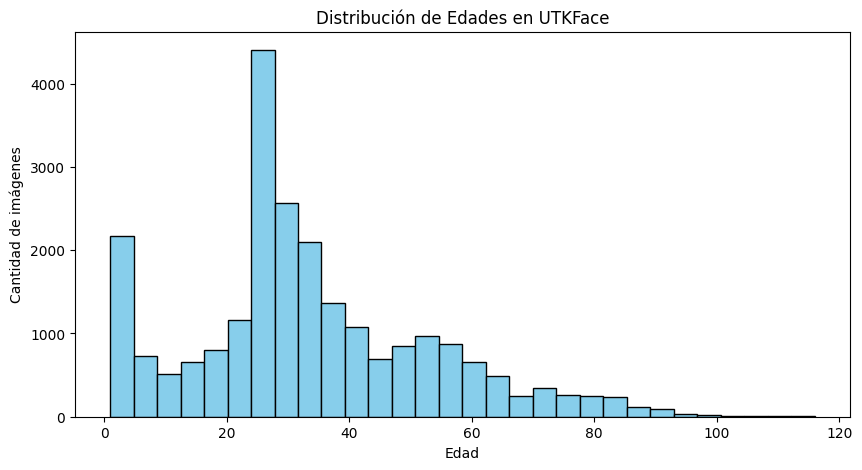

,filepath,age
0,/content/UTKFace/24_0_2_20170116165054448.jpg....,24
1,/content/UTKFace/40_1_3_20170117133747258.jpg....,40
2,/content/UTKFace/38_1_1_20170113183305653.jpg....,38
3,/content/UTKFace/58_1_0_20170109015200826.jpg....,58
4,/content/UTKFace/48_0_0_20170117160506440.jpg....,48


In [4]:
dataset_path = "/content/UTKFace"

file_paths = []
ages = []

# Procesar imágenes y extraer la edad exacta del nombre del archivo
if os.path.exists(dataset_path):
    print("Procesando archivos...")
    for file in os.listdir(dataset_path):
        if file.endswith(".jpg"):
            parts = file.split("_")
            if len(parts) >= 1 and parts[0].isdigit():
                age = int(parts[0])
                # En teoría el dataset tiene edades hasta 116 (validación x si acaso)
                if age <= 116:
                    file_paths.append(os.path.join(dataset_path, file))
                    ages.append(age)

    print(f"Total imágenes válidas: {len(file_paths)}")

df = pd.DataFrame({'filepath': file_paths, 'age': ages})

# Ver la distribución de las edades
plt.figure(figsize=(10, 5))
plt.hist(df['age'], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribución de Edades en UTKFace")
plt.xlabel("Edad")
plt.ylabel("Cantidad de imágenes")
plt.show()

display(df.head())

In [5]:
from sklearn.model_selection import train_test_split

In [6]:

# Separación de datos: 80% Entrenamiento, 10% Validación, 10% Test
df_temp, df_test = train_test_split(df, test_size=0.1, random_state=5)
df_train, df_val = train_test_split(df_temp, test_size=0.11, random_state=5)

print(f"Imágenes para entrenamiento: {len(df_train)}")
print(f"Imágenes para validación: {len(df_val)}")
print(f"Imágenes para test: {len(df_test)}")

Imágenes para entrenamiento: 18989
Imágenes para validación: 2348
Imágenes para test: 2371


## Pipeline de Datos Optimizado

In [7]:
import tensorflow as tf

In [8]:
IMG_SIZE = (200, 200)
BATCH_SIZE = 32

def procesar_imagen(filepath, label):
    # Leer, decodificar, redimensionar y normalizar
    raw_image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(raw_image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

def create_dataset(df_subset, shuffle=False):
    paths = df_subset['filepath'].values
    labels = df_subset['age'].values # el target ahora es la edad exacta
    labels = labels.astype(np.float32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        # Shuffle ANTES del map evita saturar la RAM
        dataset = dataset.shuffle(buffer_size=len(df_subset))

    dataset = dataset.map(procesar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    return dataset

ds_train = create_dataset(df_train, shuffle=True)
ds_val = create_dataset(df_val)
ds_test = create_dataset(df_test)

## Definición del Modelo (Regresión)

In [9]:
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import Sequential

In [25]:
def crear_modelo_regresion():
    model = models.Sequential([
        layers.InputLayer(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

        layers.Conv2D(16, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3, 3)),
        layers.Dropout(0.25),

        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # layers.Flatten(),
        # Usamos GlobalAveragePooling2D para evitar exceso de parámetros
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),

        # CAPA DE SALIDA: 1 sola neurona y activación 'linear'
        layers.Dense(1, activation='linear')
    ])

    # LOSS: Error Cuadrático Medio. METRIC: Error Absoluto Medio
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.0005),
        loss='mse',
        metrics=['mae',tf.keras.metrics.RootMeanSquaredError(name='rmse')]
    )
    return model

modelo_regresion = crear_modelo_regresion()
modelo_regresion.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 198, 198, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 198, 198, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 66, 66, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 66, 66, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 30, 30, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 30, 30, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,937 (234.13 KB)

 Trainable params: 59,329 (231.75 KB)

 Non-trainable params: 608 (2.38 KB)

In [ ]:
# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

checkpoint_path = "/content/drive/MyDrive/modelo_regresion_edad.keras"
checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_rmse', # Guardamos el que tenga menor RMSE de validación
    save_best_only=True,
    mode='min', # Como es RMSE (error), buscamos que sea lo MINIMO posible
    verbose=1
)

EPOCHS = 30

print("Comenzando el entrenamiento del modelo de regresión...")
historial_regresion = modelo_regresion.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS,
    callbacks=[early_stop, checkpoint]
)

Comenzando el entrenamiento del modelo de regresión...
Epoch 1/30
594/594 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 1360.2984 - mae: 31.7643 - rmse: 36.8588
Epoch 1: val_rmse improved from None to 43.57602, saving model to /content/drive/MyDrive/modelo_regresion_edad.keras

Epoch 1: finished saving model to /content/drive/MyDrive/modelo_regresion_edad.keras
594/594 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - loss: 1168.2891 - mae: 29.1807 - rmse: 34.1802 - val_loss: 1898.8693 - val_mae: 39.4722 - val_rmse: 43.5760
Epoch 2/30
591/594 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 512.3750 - mae: 17.9020 - rmse: 22.5552
Epoch 2: val_rmse improved from 43.57602 to 26.43884, saving model to /content/drive/MyDrive/modelo_regresion_edad.keras

Epoch 2: finished saving model to /content/drive/MyDrive/modelo_regresion_edad.keras
594/594 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - loss: 396.0527 - mae: 15.3009 - rmse: 19.9011 - val_loss: 699.0124 - val_mae: 22.1485 - val_rmse: 26.4388
Epoch 3/30
592/594 ━━━━━━━━━

## Evaluación de Resultados

In [12]:
# # Graficar
# mae = historial_regresion.history['mae']
# val_mae = historial_regresion.history['val_mae']
# loss = historial_regresion.history['loss'] # MSE
# val_loss = historial_regresion.history['val_loss']

# epocas = range(1, len(mae) + 1)

# plt.figure(figsize=(14, 5))
# plt.subplot(1, 2, 1)
# plt.plot(epocas, mae, 'b-', label='MAE Entrenamiento')
# plt.plot(epocas, val_mae, 'r-', label='MAE Validación')
# plt.title('Error Absoluto Medio (MAE) - (Margen de equivocación en años)')
# plt.xlabel('Épocas')
# plt.ylabel('Años Diferencia')
# plt.legend()

# plt.subplot(1, 2, 2)
# plt.plot(epocas, loss, 'b-', label='MSE Entrenamiento')
# plt.plot(epocas, val_loss, 'r-', label='MSE Validación')
# plt.title('Error Cuadrático Medio (Loss)')
# plt.xlabel('Épocas')
# plt.ylabel('MSE')
# plt.legend()

# plt.tight_layout()
# plt.show()

# print("\nEvaluando con el conjunto de pruebas...")
# test_loss, test_mae = modelo_regresion.evaluate(ds_test, verbose=0)
# print(f"El modelo se equivoca en promedio por: {test_mae:.2f} años.")

In [13]:
# # Ver predicciones visualmente
# for imagenes, edades_reales in ds_test.take(1):
#     predicciones = modelo_regresion.predict(imagenes).flatten()

#     plt.figure(figsize=(15, 10))
#     for i in range(12):
#         ax = plt.subplot(3, 4, i + 1)
#         plt.imshow(imagenes[i].numpy())

#         real = edades_reales[i].numpy()
#         pred = predicciones[i]

#         # Color verde si el error es menor a 5 años
#         color = 'green' if abs(real - pred) <= 5 else 'orange' if abs(real - pred) <= 10 else 'red'

#         plt.title(f"Real: {int(real)} años\nPredicción: {pred:.1f} años", color=color, fontweight='bold')
#         plt.axis("off")

#     plt.tight_layout()
#     plt.show()
#     break

In [14]:
!pip install keras-tuner -q
import keras_tuner as kt
import json

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 11.9 MB/s eta 0:00:00


In [ ]:
# def build_model(hp):
#     model = Sequential()
#     model.add(layers.InputLayer(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)))
    
#     # Capa Convolucional 1 variable
#     filters_1 = hp.Int('conv_1_filter', min_value=32, max_value=64, step=32)
#     model.add(layers.Conv2D(filters_1, (3, 3), activation='relu'))
#     model.add(layers.MaxPooling2D((2, 2)))
    
#     # Capa Convolucional 2 variable
#     filters_2 = hp.Int('conv_2_filter', min_value=64, max_value=128, step=64)
#     model.add(layers.Conv2D(filters_2, (3, 3), activation='relu'))
#     model.add(layers.MaxPooling2D((2, 2)))
    
#     # Capa Convolucional 3 opcional o variable
#     filters_3 = hp.Int('conv_3_filter', min_value=128, max_value=256, step=128)
#     model.add(layers.Conv2D(filters_3, (3, 3), activation='relu'))
#     model.add(layers.MaxPooling2D((2, 2)))
    
#     # Aplanado (usamos GlobalAveragePooling2D para eficiencia)
#     model.add(layers.GlobalAveragePooling2D())
    
#     # Capa Densa variable
#     units_1 = hp.Int('dense_1_units', min_value=128, max_value=512, step=128)
#     model.add(tf.keras.layers.Dense(units_1, activation='relu'))
    
#     # Dropout variable
#     dropout_1 = hp.Float('dropout_1', min_value=0.2, max_value=0.5, step=0.1)
#     model.add(tf.keras.layers.Dropout(dropout_1))
    
#     # Capa de Salida para regresión
#     model.add(tf.keras.layers.Dense(1, activation='linear'))
    
#     # Optimización: Learning rate variable
#     hp_learning_rate = hp.Choice('learning_rate', values=[1e-3, 5e-4, 1e-4])
    
#     model.compile(
#         optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
#         loss='mse',
#         metrics=[tf.keras.metrics.RootMeanSquaredError(name='rmse'), 'mae']
#     )
    
#     return model

# # Configurar el Tuner usando Hyperband
# tuner = kt.Hyperband(
#     build_model,
#     objective=kt.Objective('val_rmse', direction='min'), # Buscamos minimizar el RMSE de la validación
#     max_epochs=10,
#     factor=3,
#     directory='/content/tuner',
#     project_name='tuning_edad_cnn'
# )

# # Detener el entrenamiento temprano si no mejora según el RMSE
# stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_rmse', patience=4, restore_best_weights=True)

# print("Iniciando la búsqueda del mejor modelo...")
# tuner.search(
#     ds_train,
#     validation_data=ds_val,
#     epochs=15,
#     callbacks=[stop_early]
# )

# # Resumen de los mejores hiperparámetros encontrados
# best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
# print("\n=== MEJORES HIPERPARÁMETROS ENCONTRADOS ===")
# print(f"Learning Rate: {best_hps.get('learning_rate')}")
# print(f"Filtros Conv 1: {best_hps.get('conv_1_filter')}")
# print(f"Filtros Conv 2: {best_hps.get('conv_2_filter')}")
# print(f"Filtros Conv 3: {best_hps.get('conv_3_filter')}")
# print(f"Unidades Densas: {best_hps.get('dense_1_units')}")
# print(f"Dropout: {best_hps.get('dropout_1')}")

# # Guardar los mejores hiperparámetros en un archivo JSON para uso posterior
# with open('/content/drive/MyDrive/tuner/regresion/best_hyperparameters.json', 'w') as f:
#     json.dump(best_hps.values, f, indent=4)

# print("\n Hiperparametros guardados")

Trial 30 Complete [00h 08m 21s]
val_rmse: 15.990910530090332

Best val_rmse So Far: 13.843404769897461
Total elapsed time: 01h 24m 10s

=== MEJORES HIPERPARÁMETROS ENCONTRADOS ===
Learning Rate: 0.001
Filtros Conv 1: 32
Filtros Conv 2: 128
Filtros Conv 3: 256
Unidades Densas: 512
Dropout: 0.2


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/tuner/regresion/best_hyperparameters.json'